In [37]:
import sys
import pandas as pd
import numpy as np
import requests
from bs4 import BeautifulSoup
from io import BytesIO, StringIO
from pathlib import Path
from urllib.parse import urljoin

print(sys.executable)

/Users/clairek/Desktop/SDPA/summative-coursework-v1/Component2/.venv/bin/python


# 2.1 Collect and clean international visits to London data

In [ ]:
# 1. Dataset webpage
page_url = (
    "https://www.data.gov.uk/dataset/"
    "08ff246b-176a-40cc-af3c-2076dfbb7a92/"
    "number-of-international-visitors-to-london1"
)

# 2. Scrape the webpage
response = requests.get(page_url, timeout=30)
response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")

# 3. Find the CSV download link
csv_url = None

for link in soup.find_all("a", href=True):
    href = link["href"]
    if "international-visitors-london-raw.csv" in href:
        csv_url = urljoin(page_url, href)
        break

if csv_url is None:
    raise ValueError("CSV download link not found")

print("CSV URL:", csv_url)

# 4. Download the CSV
csv_response = requests.get(csv_url, timeout=60)
csv_response.raise_for_status()

# 5. Save the original dataset
Path("datasets").mkdir(exist_ok=True)

Path("datasets/international-visitors-london-raw.csv").write_bytes(
    csv_response.content
)

# 6. Load into pandas
rawdata = pd.read_csv(
    BytesIO(csv_response.content),
    encoding="cp1252"
)

print(rawdata.shape)
print(rawdata.head())

CSV URL: https://data.london.gov.uk/download/20opj/b1e0f953-4c8a-4b45-95f5-e0d143d5641e/international-visitors-london-raw.csv
(61462, 11)
   year        quarter   market     dur_stay mode        purpose     area  \
0  2002  January-March  Belgium  1-3  nights  Air        Holiday   LONDON   
1  2002  January-March  Belgium  1-3  nights  Air       Business   LONDON   
2  2002  January-March  Belgium  1-3  nights  Air            VFR   LONDON   
3  2002  January-March  Belgium  1-3  nights  Air  Miscellaneous   LONDON   
4  2002  January-March  Belgium  1-3  nights  Sea       Business   LONDON   

   Visits (000s)  Spend (£m)  Nights (000s)  sample  
0       3.572186    0.969138       6.954456       5  
1       9.284226    2.399577      12.604959      19  
2       0.877182    0.089833       2.153128       3  
3       0.163874    0.010160       0.163874       1  
4       1.648670    0.016789       1.650300       1  


In [39]:
# checking the original data
print("Missing_value")
print(rawdata.isna().sum())
print("\n Shape")
print(rawdata.shape)

rawdata.head()

Missing_value
year             0
quarter          0
market           0
dur_stay         0
mode             0
purpose          0
area             0
Visits (000s)    0
Spend (£m)       0
Nights (000s)    0
sample           0
dtype: int64

 Shape
(61462, 11)


,year,quarter,market,dur_stay,mode,purpose,area,Visits (000s),Spend (£m),Nights (000s),sample
0,2002,January-March,Belgium,1-3 nights,Air,Holiday,LONDON,3.572186,0.969138,6.954456,5
1,2002,January-March,Belgium,1-3 nights,Air,Business,LONDON,9.284226,2.399577,12.604959,19
2,2002,January-March,Belgium,1-3 nights,Air,VFR,LONDON,0.877182,0.089833,2.153128,3
3,2002,January-March,Belgium,1-3 nights,Air,Miscellaneous,LONDON,0.163874,0.010160,0.163874,1
4,2002,January-March,Belgium,1-3 nights,Sea,Business,LONDON,1.648670,0.016789,1.650300,1


In [40]:
# making a datafram with year between 2010-2019 / 10y)
visits_df = rawdata.copy()

visits_df["year"] = pd.to_numeric(visits_df["year"], errors="coerce")

visits_df = visits_df[visits_df["year"].between(2010, 2019)].copy()
visits_df["year"] = visits_df["year"].astype(int)


In [41]:
visits_df['visits'] = (visits_df['Visits (000s)']*1000).round().astype(int)
visits_df['spend_gbp'] = (visits_df['Spend (£m)']*1000000).round().astype(int)
visits_df['total_nights'] = (visits_df['Nights (000s)']*1000).round().astype(int)

visits_df = visits_df.drop(columns = ['Visits (000s)', 'Spend (£m)', 'Nights (000s)'])

visits_df = visits_df.rename(columns={
    "market": "country",
    "dur_stay": "stay_nights",
    "mode": "transport",
    "purpose": "purpose",
    "sample": "sample_size"
})

visits_df = visits_df[['year',
 'quarter',
 'country',
 'purpose',
 'visits',
 'spend_gbp',
 'total_nights',
 'stay_nights',
 'sample_size',
 'transport', 
 'area']]

visits_df.head()

,year,quarter,country,purpose,visits,spend_gbp,total_nights,stay_nights,sample_size,transport,area
27065,2010,January-March,Belgium,Holiday,1881,695745,4297,1-3 nights,3,Air,LONDON
27066,2010,January-March,Belgium,Business,5801,3532986,11905,1-3 nights,8,Air,LONDON
27067,2010,January-March,Belgium,VFR,873,401441,1348,1-3 nights,2,Air,LONDON
27068,2010,January-March,Belgium,Miscellaneous,1112,74910,1112,1-3 nights,4,Air,LONDON
27069,2010,January-March,Belgium,Holiday,6719,1867432,14160,1-3 nights,6,Sea,LONDON


In [42]:
#checking the 20 highest visits country
top20 = visits_df.groupby('country')['visits'].sum()
top20 = top20.sort_values(ascending = False).head(20)
top20

country
USA                     23685070
France                  18058596
Germany                 13541220
Italy                   12807796
Spain                   11290169
Irish Republic           7163859
Netherlands              7032660
Australia                5995869
Belgium                  4885513
Sweden                   4761943
Switzerland              4612528
Canada                   4353308
Poland                   4300257
Norway                   3881632
Denmark                  3412822
India                    3354866
China                    3340352
Other Eastern Europe     3318999
Japan                    2646805
Portugal                 2311113
Name: visits, dtype: int64

In [43]:
selected_countries = [
    "France", "Germany", "Italy", "Spain",
    "USA", "Australia", "India", "China", "Japan"
]

visits_df = visits_df[
    visits_df["country"].isin(selected_countries)
].copy()

visits_df.head()

,year,quarter,country,purpose,visits,spend_gbp,total_nights,stay_nights,sample_size,transport,area
27093,2010,January-March,France,Holiday,30250,9161918,74183,1-3 nights,44,Air,LONDON
27094,2010,January-March,France,Business,15300,5058597,28300,1-3 nights,25,Air,LONDON
27095,2010,January-March,France,VFR,11790,2817001,25084,1-3 nights,17,Air,LONDON
27096,2010,January-March,France,Study,757,375636,2005,1-3 nights,1,Air,LONDON
27097,2010,January-March,France,Miscellaneous,7522,1826384,9807,1-3 nights,15,Air,LONDON


In [44]:
# clearning data and adding a currency column
visits_df['quarter'] = visits_df['quarter'].replace({
    "January-March": 1,
    "April-June": 2,
    "July-September": 3,
    "October-December": 4
})
visits_df["stay_nights"] = (
    visits_df["stay_nights"]
    .str.replace("nights", "", regex=False)
    .str.replace("night", "", regex=False)
    .str.strip()
)
visits_df["year"] = visits_df["year"].astype(int)

currency_map = {
    "France": "EUR",
    "Germany": "EUR",
    "Italy": "EUR",
    "Spain": "EUR",
    "USA": "USD",
    "Australia": "AUD",
    "India": "INR",
    "China": "CNY",
    "Japan": "JPY"
}

visits_df["currency"] = visits_df["country"].map(currency_map)

visits_df.groupby("currency")["visits"].sum()

currency
AUD     5995869
CNY     3340352
EUR    55697781
INR     3354866
JPY     2646805
USD    23685070
Name: visits, dtype: int64

In [45]:
# featuring 'spend per visit' column by currecy group and visit of purpose
quarterly_visits = (
    visits_df.groupby(
        ["year", "quarter", "currency", "purpose"],
        as_index = False
    )
    .agg(
        visits=("visits", "sum"),
        spend_gbp=("spend_gbp", "sum")
    )
)
quarterly_visits["spend_per_visit"] = quarterly_visits["spend_gbp"] / quarterly_visits["visits"]


In [46]:
print(quarterly_visits['year'].unique())
print(quarterly_visits['quarter'].unique())
print(quarterly_visits['currency'].unique())
print(quarterly_visits['purpose'].unique())
quarterly_visits.describe()

[2010 2011 2012 2013 2014 2015 2016 2017 2018 2019]
[1 2 3 4]
<StringArray>
['AUD', 'CNY', 'EUR', 'INR', 'JPY', 'USD']
Length: 6, dtype: str
<StringArray>
['Business', 'Holiday', 'Miscellaneous', 'Study', 'VFR']
Length: 5, dtype: str


,year,quarter,visits,spend_gbp,spend_per_visit
count,1119.000000,1119.000000,1.119000e+03,1.119000e+03,1119.000000
mean,2014.502234,2.496872,8.464767e+04,5.240886e+07,1352.394264
std,2.884439,1.114123,1.616491e+05,7.787564e+07,2538.176474
min,2010.000000,1.000000,1.850000e+02,1.534400e+04,21.685969
25%,2012.000000,2.000000,7.147000e+03,7.701772e+06,474.424066
50%,2015.000000,3.000000,2.121400e+04,2.244017e+07,746.699610
75%,2017.000000,3.000000,7.243450e+04,5.564561e+07,1420.534331
max,2019.000000,4.000000,1.017167e+06,4.499620e+08,49118.241792


# 2.2 Collect and clean exchange rate data


In [47]:
import requests
import pandas as pd
from bs4 import BeautifulSoup
from io import StringIO

url = (
    "https://www.bankofengland.co.uk/"
    "boeapps/database/fromshowcolumns.asp"
)

params = {
    "Travel": "NIxIRxSUx",
    "FromSeries": "1",
    "ToSeries": "50",
    "DAT": "RNG",
    "FD": "1",
    "FM": "Jan",
    "FY": "2010",
    "TD": "31",
    "TM": "Dec",
    "TY": "2019",
    "CSVF": "TT",
    "html.x": "122",
    "html.y": "24",
    "C": ["DKW", "NSC", "NS9", "DL2", "DL7", "DLM"],
    "Filter": "N"
}

response = requests.get(
    url,
    params=params,
    headers={"User-Agent": "UKCitiesStudy/1.0"},
    timeout=60
)

response.raise_for_status()

print("Status:", response.status_code)
print("Content type:", response.headers.get("Content-Type"))

soup = BeautifulSoup(response.text, "html.parser")

tables = soup.find_all("table")

print("Number of tables:", len(tables))

for i, table in enumerate(tables):
    print(f"\nTable {i}:")
    print(table.get_text(" ", strip=True)[:500])

Status: 200
Content type: text/html
Number of tables: 2

Table 0:
Date Quarterly average Spot exchange rate, Australian Dollar into Sterling XUQAADS Quarterly average spot exchange rate, Chinese Yuan into Sterling XUQABK89 Quarterly average spot exchange rate, Indian Rupee into Sterling XUQABK97 Quarterly average Spot exchange rate, Euro into Sterling XUQAERS Quarterly average Spot exchange rate, Japanese Yen into Sterling XUQAJYS Quarterly average Spot exchange rate, US $ into Sterling XUQAUSS 31 Mar 10 1.7235 10.6392 71.4874 1.1269 141.3355 1.5584 30 Jun 10 

Table 1:
Necessary cookies Analytics cookies Yes Yes Accept recommended cookies Yes No Proceed with necessary cookies only


In [48]:
fx_df= pd.read_html(StringIO(str(tables[0])))[0]

print(fx_df.shape)
print(fx_df.columns.tolist())
print(fx_df.head())

(40, 7)
['Date', 'Quarterly average Spot exchange rate, Australian Dollar into Sterling XUQAADS', 'Quarterly average spot exchange rate, Chinese Yuan into Sterling XUQABK89', 'Quarterly average spot exchange rate, Indian Rupee into Sterling XUQABK97', 'Quarterly average Spot exchange rate, Euro into Sterling XUQAERS', 'Quarterly average Spot exchange rate, Japanese Yen into Sterling XUQAJYS', 'Quarterly average Spot exchange rate, US $ into Sterling XUQAUSS']
        Date  \
0  31 Mar 10   
1  30 Jun 10   
2  30 Sep 10   
3  31 Dec 10   
4  31 Mar 11   

   Quarterly average Spot exchange rate, Australian Dollar into Sterling XUQAADS  \
0                                             1.7235                               
1                                             1.6922                               
2                                             1.7150                               
3                                             1.6009                               
4                  

In [49]:
fx_df = fx_df.rename(columns={
                    'Quarterly average Spot exchange rate, Australian Dollar into Sterling XUQAADS': "AUD",
                    'Quarterly average spot exchange rate, Chinese Yuan into Sterling XUQABK89': 'CNY',
                    'Quarterly average spot exchange rate, Indian Rupee into Sterling XUQABK97': 'INR',
                    'Quarterly average Spot exchange rate, Euro into Sterling XUQAERS': 'EUR',
                    'Quarterly average Spot exchange rate, Japanese Yen into Sterling XUQAJYS': 'JPY',
                    'Quarterly average Spot exchange rate, US $ into Sterling XUQAUSS': 'USD'
                    }
)
print(fx_df.isna().sum())
print(fx_df.shape)
print(fx_df.head())

Date    0
AUD     0
CNY     0
INR     0
EUR     0
JPY     0
USD     0
dtype: int64
(40, 7)
        Date     AUD      CNY      INR     EUR       JPY     USD
0  31 Mar 10  1.7235  10.6392  71.4874  1.1269  141.3355  1.5584
1  30 Jun 10  1.6922  10.1734  68.0141  1.1747  137.2062  1.4909
2  30 Sep 10  1.7150  10.4967  71.9827  1.1995  133.0108  1.5510
3  31 Dec 10  1.6009  10.5237  70.8754  1.1639  130.5153  1.5811
4  31 Mar 11  1.5955  10.5470  72.5471  1.1710  131.9404  1.6034


In [50]:
fx_df["Date"] = pd.to_datetime(fx_df["Date"], format="%d %b %y")

fx_df["year"] = fx_df["Date"].dt.year
fx_df["quarter"] = fx_df["Date"].dt.quarter

# Remove Date and reorder columns
fx_df = fx_df[
    ["year", "quarter", "AUD", "CNY", "INR", "EUR", "JPY", "USD"]
]

print(fx_df.head())

   year  quarter     AUD      CNY      INR     EUR       JPY     USD
0  2010        1  1.7235  10.6392  71.4874  1.1269  141.3355  1.5584
1  2010        2  1.6922  10.1734  68.0141  1.1747  137.2062  1.4909
2  2010        3  1.7150  10.4967  71.9827  1.1995  133.0108  1.5510
3  2010        4  1.6009  10.5237  70.8754  1.1639  130.5153  1.5811
4  2011        1  1.5955  10.5470  72.5471  1.1710  131.9404  1.6034


# 2.3 Collect and clean UK inflation data

In [51]:
# ONS CPI index API
url = (
    "https://www.ons.gov.uk/economy/"
    "inflationandpriceindices/timeseries/d7bt/mm23/data"
)

response = requests.get(url, timeout=60)
response.raise_for_status()

data = response.json()

print(data)
# Extract monthly observations
cpi_df = pd.DataFrame(data["quarters"])

print(cpi_df.columns.tolist())
print(cpi_df.head())


{'years': [{'date': '1988', 'value': '49.6', 'label': '1988', 'year': '1988', 'month': '', 'quarter': '', 'sourceDataset': 'MM23', 'updateDate': '2016-01-19T09:30:00.000Z'}, {'date': '1989', 'value': '52.2', 'label': '1989', 'year': '1989', 'month': '', 'quarter': '', 'sourceDataset': 'MM23', 'updateDate': '2016-01-19T09:30:00.000Z'}, {'date': '1990', 'value': '55.9', 'label': '1990', 'year': '1990', 'month': '', 'quarter': '', 'sourceDataset': 'MM23', 'updateDate': '2018-12-19T00:00:00.000Z'}, {'date': '1991', 'value': '60.1', 'label': '1991', 'year': '1991', 'month': '', 'quarter': '', 'sourceDataset': 'MM23', 'updateDate': '2018-12-19T00:00:00.000Z'}, {'date': '1992', 'value': '62.6', 'label': '1992', 'year': '1992', 'month': '', 'quarter': '', 'sourceDataset': 'MM23', 'updateDate': '2016-01-19T09:30:00.000Z'}, {'date': '1993', 'value': '64.2', 'label': '1993', 'year': '1993', 'month': '', 'quarter': '', 'sourceDataset': 'MM23', 'updateDate': '2016-01-19T09:30:00.000Z'}, {'date': '1

In [52]:
# Keep only the columns needed
cpi_df = cpi_df[["year", "quarter", "value"]].copy()

# Rename the CPI value column
cpi_df = cpi_df.rename(columns={"value": "cpi_index"})

# Convert data types and filter 2010 - 2019
cpi_df["year"] = pd.to_numeric(cpi_df["year"])
cpi_df["quarter"] = (
    cpi_df["quarter"]
    .str.replace("Q", "", regex=False)
    .astype(int)
)

cpi_df["cpi_index"] = pd.to_numeric(cpi_df["cpi_index"])

cpi_df = cpi_df[cpi_df["year"].between(2010, 2019)].copy()

# Sort chronologically
cpi_df = (
    cpi_df
    .sort_values(["year", "quarter"])
    .reset_index(drop=True)
)

print(cpi_df.isna().sum())
print(cpi_df.head())
print(cpi_df.shape)

year         0
quarter      0
cpi_index    0
dtype: int64
   year  quarter  cpi_index
0  2010        1       88.2
1  2010        2       89.3
2  2010        3       89.6
3  2010        4       90.5
4  2011        1       91.8
(40, 3)


## 2.4 Data Merge

In [53]:
#creataing year and quarter for key to lookup

fx_lookup = fx_df.set_index(["year", "quarter"], verify_integrity=True)
fx_lookup.head()

/var/folders/93/dz_8fh6104x97ksqhx98m8qr0000gn/T/ipykernel_987/1137649502.py:3: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  fx_lookup = fx_df.set_index(["year", "quarter"], verify_integrity=True)


AUD      CNY      INR     EUR       JPY     USD
year quarter                                                    
2010 1        1.7235  10.6392  71.4874  1.1269  141.3355  1.5584
     2        1.6922  10.1734  68.0141  1.1747  137.2062  1.4909
     3        1.7150  10.4967  71.9827  1.1995  133.0108  1.5510
     4        1.6009  10.5237  70.8754  1.1639  130.5153  1.5811
2011 1        1.5955  10.5470  72.5471  1.1710  131.9404  1.6034

In [54]:
# creating analysis_df and merging exchange rate into visits data

analysis_df = quarterly_visits.copy()
analysis_df["exchange_rate"] = analysis_df.apply(
    lambda row: fx_lookup.loc[
        (row["year"], row["quarter"]), row["currency"]],
    axis=1
)

analysis_df.head()    

,year,quarter,currency,purpose,visits,spend_gbp,spend_per_visit,exchange_rate
0,2010,1,AUD,Business,12275,19089357,1555.141100,1.7235
1,2010,1,AUD,Holiday,34090,19609919,575.239630,1.7235
2,2010,1,AUD,Miscellaneous,6276,1071196,170.681326,1.7235
3,2010,1,AUD,Study,196,23846,121.663265,1.7235
4,2010,1,AUD,VFR,29440,17396489,590.913349,1.7235


In [55]:
# merging inflation rate into analysis_df

analysis_df = analysis_df.merge(
    cpi_df,
    on=["year", "quarter"],
    how="left",
    validate="many_to_one"
)
analysis_df.head()

,year,quarter,currency,purpose,visits,spend_gbp,spend_per_visit,exchange_rate,cpi_index
0,2010,1,AUD,Business,12275,19089357,1555.141100,1.7235,88.2
1,2010,1,AUD,Holiday,34090,19609919,575.239630,1.7235,88.2
2,2010,1,AUD,Miscellaneous,6276,1071196,170.681326,1.7235,88.2
3,2010,1,AUD,Study,196,23846,121.663265,1.7235,88.2
4,2010,1,AUD,VFR,29440,17396489,590.913349,1.7235,88.2


In [56]:
# validate the result

print("Shape:", analysis_df.shape)

print("\nMissing values:")
print(analysis_df.isna().sum())

assert len(analysis_df) == len(quarterly_visits)
assert analysis_df["exchange_rate"].notna().all()
assert analysis_df["cpi_index"].notna().all()

Shape: (1119, 9)

Missing values:
year               0
quarter            0
currency           0
purpose            0
visits             0
spend_gbp          0
spend_per_visit    0
exchange_rate      0
cpi_index          0
dtype: int64


In [57]:
# Inflation adjusted total expenditure
analysis_df["real_spend_gbp"] = analysis_df["spend_gbp"] * 100 / analysis_df["cpi_index"]
# Inflation adjusted expenditure per visit
analysis_df["real_spend_per_visit"] = analysis_df["spend_per_visit"] * 100 / analysis_df["cpi_index"]

In [58]:
analysis_df.head()

,year,quarter,currency,purpose,visits,spend_gbp,spend_per_visit,exchange_rate,cpi_index,real_spend_gbp,real_spend_per_visit
0,2010,1,AUD,Business,12275,19089357,1555.141100,1.7235,88.2,2.164326e+07,1763.198526
1,2010,1,AUD,Holiday,34090,19609919,575.239630,1.7235,88.2,2.223347e+07,652.199127
2,2010,1,AUD,Miscellaneous,6276,1071196,170.681326,1.7235,88.2,1.214508e+06,193.516242
3,2010,1,AUD,Study,196,23846,121.663265,1.7235,88.2,2.703628e+04,137.940210
4,2010,1,AUD,VFR,29440,17396489,590.913349,1.7235,88.2,1.972391e+07,669.969784


## 3. EDA

In [59]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.dates as mdates

eda_df = analysis_df.copy()

eda_df["date"] = pd.to_datetime({
    "year": eda_df["year"],
    "month": eda_df["quarter"] * 3 - 2,
    "day": 1
})

eda_df = eda_df.sort_values("date")

In [60]:
#renaming x and y lims for graphs
market_names = {
    "AUD": "Australia",
    "CNY": "China",
    "EUR": "4 EU countries",
    "INR": "India",
    "JPY": "Japan",
    "USD": "USA"
}

purpose_colors = {
    "Holiday": "#4C78A8",
    "Business": "#F58518",
    "VFR": "#54A24B",
    "Study": "#B279A2",
    "Miscellaneous": "#9D755D"
}

In [61]:
# accounting the total number of visits grouped by currency and purpose
purpose_visits = (
    analysis_df.groupby(["currency", "purpose"])["visits"]
    .sum()
    .unstack(fill_value=0)
)

display(purpose_visits)

purpose,Business,Holiday,Miscellaneous,Study,VFR
currency,,,,,
AUD,501321,3245833,450494,13422,1784799
CNY,561181,2099309,161741,112818,405303
EUR,9331507,31088081,2227413,581594,12469186
INR,781949,1377678,188075,41126,966038
JPY,687509,1543956,100315,56511,258514
USD,5366712,11482713,2290179,311230,4234236


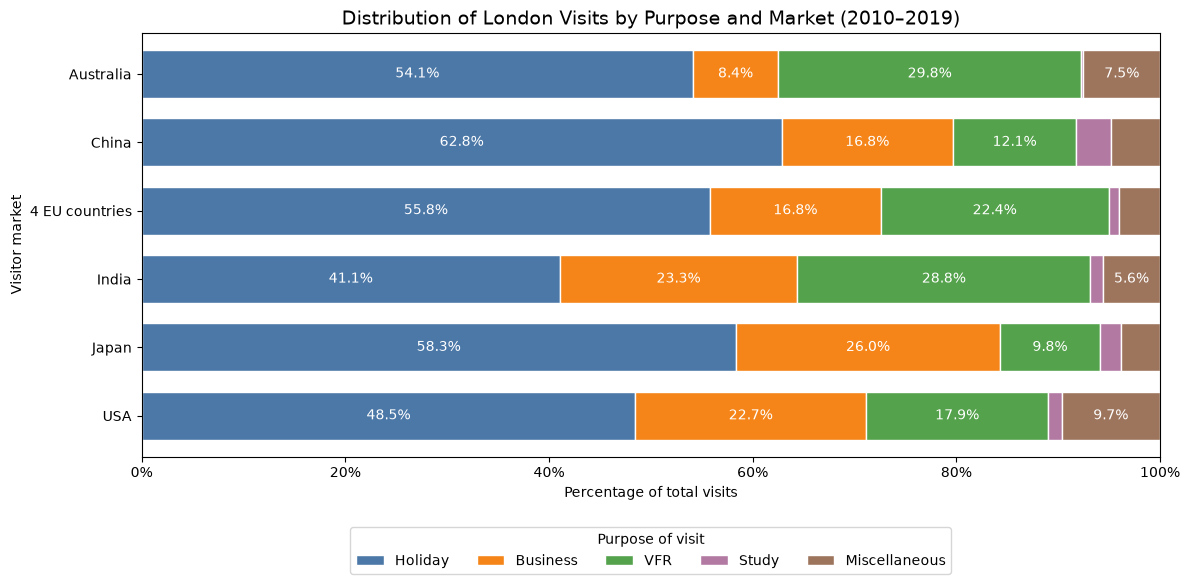

In [62]:
purpose_order = ["Holiday", "Business", "VFR", "Study", "Miscellaneous"]

def plot_purpose_share(totals, title, xlabel):
    """Plot market-level percentages by travel purpose from a totals table."""
    percentages = totals.div(totals.sum(axis=1), axis=0) * 100
    percentages = percentages.reindex(columns=purpose_order, fill_value=0)
    percentages = percentages.rename(index=market_names)

    ax = percentages.plot(
        kind="barh", stacked=True, figsize=(12, 6),
        color=[purpose_colors[p] for p in purpose_order],
        width=0.7, edgecolor="white"
    )
    ax.set_title(title, fontsize=14)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Visitor market")
    ax.set_xlim(0, 100)
    ax.xaxis.set_major_formatter(ticker.PercentFormatter(xmax=100))
    ax.legend(title="Purpose of visit", loc="upper center",
              bbox_to_anchor=(0.5, -0.15), ncol=5)
    ax.invert_yaxis()

    for bars in ax.containers:
        labels = [f"{bar.get_width():.1f}%" if bar.get_width() >= 5 else ""
                  for bar in bars]
        ax.bar_label(bars, labels=labels, label_type="center",
                     fontsize=10, color="white")
    plt.tight_layout()
    plt.show()

plot_purpose_share(
    purpose_visits,
    "Distribution of London Visits by Purpose and Market (2010–2019)",
    "Percentage of total visits"
)

In [63]:
purpose_spend = (
    analysis_df.groupby(["currency", "purpose"])["real_spend_gbp"]
    .sum()
    .unstack(fill_value=0)
)

display(purpose_spend)

purpose,Business,Holiday,Miscellaneous,Study,VFR
currency,,,,,
AUD,9.396657e+08,2.387524e+09,2.480604e+08,2.775083e+07,1.276027e+09
CNY,9.760918e+08,2.529638e+09,3.335110e+08,7.268217e+08,4.898249e+08
EUR,5.192103e+09,1.287731e+10,1.273348e+09,9.821995e+08,3.720377e+09
INR,1.138218e+09,8.064153e+08,2.226163e+08,9.337136e+07,5.228376e+08
JPY,7.558920e+08,1.166668e+09,8.431811e+07,2.910624e+08,1.594737e+08
USD,7.082516e+09,7.920481e+09,1.015677e+09,1.180895e+09,2.110702e+09


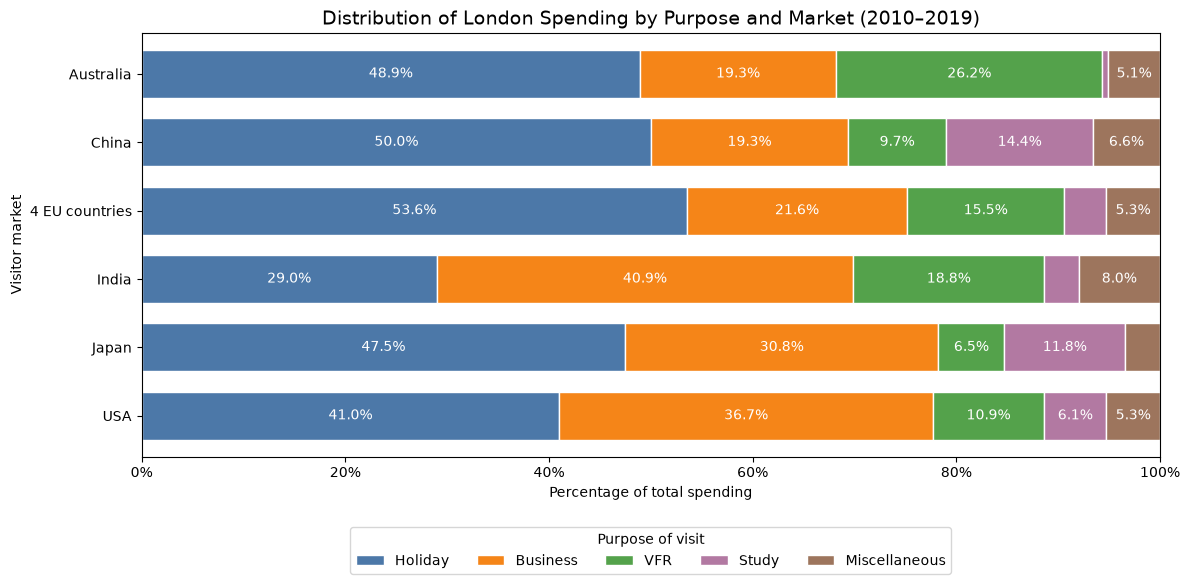

In [64]:
plot_purpose_share(
    purpose_spend,
    "Distribution of London Spending by Purpose and Market (2010–2019)",
    "Percentage of total spending"
)

### Key observations from visitor demand and expenditure distributions

India: Business visits account for 23.3% of total visits but contribute 40.9% of total expenditure, indicating relatively high expenditure per business visit.

Japan: Holiday visits represent 58.3% of total visits but account for only 47.5% of total expenditure, suggesting that holiday visitors spend less per visit than the overall market average.

China: Despite representing a relatively small proportion of total visits, study-related visits contribute 14.4% of total expenditure, highlighting their economic significance.

Australia: Visiting Friends and Relatives (VFR) accounts for 29.8% of total visits and 26.2% of total expenditure, demonstrating the relative importance of socially motivated travel within the Australian market.

USA: Business visits represent 22.7% of total visits but contribute 36.7% of total expenditure, suggesting relatively high expenditure per business visit.

Selected EU countries: Holiday visits account for 55.8% of total visits and 53.6% of total expenditure. The relatively small difference between these shares suggests that expenditure per holiday visit is close to the overall market average.

In [65]:
# The same dated EDA dataframe is used for each selected market.
study_df = eda_df[eda_df["purpose"] == "Study"]
display(study_df.head())

,year,quarter,currency,purpose,visits,spend_gbp,spend_per_visit,exchange_rate,cpi_index,real_spend_gbp,real_spend_per_visit,date
28,2010,1,USD,Study,2902,8615793,2968.915575,1.5584,88.2,9.768473e+06,3366.117433,2010-01-01
23,2010,1,JPY,Study,787,888365,1128.799238,141.3355,88.2,1.007217e+06,1279.817730,2010-01-01
18,2010,1,INR,Study,2028,7873933,3882.609961,71.4874,88.2,8.927362e+06,4402.052109,2010-01-01
13,2010,1,EUR,Study,10995,25931784,2358.506958,1.1269,88.2,2.940112e+07,2674.044170,2010-01-01
3,2010,1,AUD,Study,196,23846,121.663265,1.7235,88.2,2.703628e+04,137.940210,2010-01-01


In [66]:
def plot_market_trend(market_df, currency, variable, ylabel, purpose):
    """Compare one market and purpose time series with its exchange rate."""
    fig, ax1 = plt.subplots(figsize=(13, 5))
    ax1.plot(
        market_df["date"], market_df[variable],
        color=purpose_colors[purpose], linewidth=2,
        marker="o", markersize=3, label=ylabel
    )
    ax1.set_xlabel("Year")
    ax1.set_ylabel(ylabel)
    ax1.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))

    ax2 = ax1.twinx()
    ax2.plot(
        market_df["date"], market_df["exchange_rate"],
        color="black", linestyle="--", linewidth=2,
        label="Exchange rate"
    )
    ax2.set_ylabel(f"Exchange rate ({currency} per GBP)")
    ax1.xaxis.set_major_locator(mdates.YearLocator())
    ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax1.legend(loc="upper left")
    ax2.legend(loc="upper right")
    ax1.grid(alpha=0.2)
    ax1.set_title(
        f"{market_names[currency]}: {ylabel} and Exchange Rate (2010–2019)"
    )
    plt.tight_layout()
    plt.show()

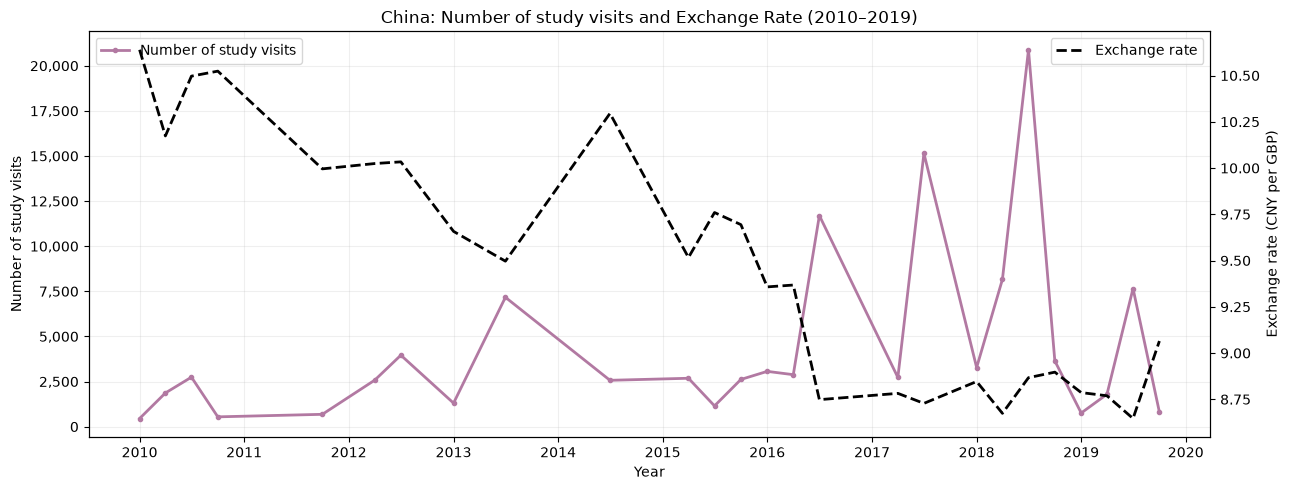

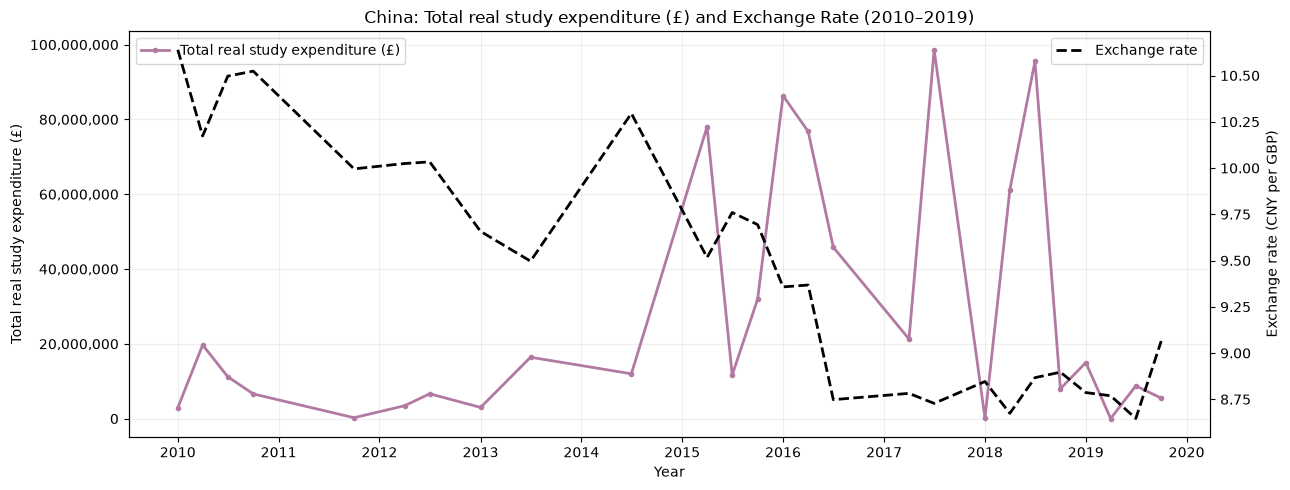

In [67]:
china_study_df = study_df[study_df["currency"] == "CNY"]
plot_market_trend(china_study_df, "CNY", "visits",
                  "Number of study visits", "Study")
plot_market_trend(china_study_df, "CNY", "real_spend_gbp",
                  "Total real study expenditure (£)", "Study")

Chinese study-related visits exhibit seasonal fluctuations, with visitor numbers appearing to peak in the third quarter. This pattern may reflect the beginning of the academic year in the UK.

An apparent negative relationship between exchange rates and visitor demand can also be observed, particularly between 2016 and 2019, when the exchange rate was approximately 10% lower than in earlier periods.

Additionally, some peaks in total expenditure are not accompanied by corresponding increases in visitor numbers. This suggests substantial variation in expenditure per visit and warrants further investigation of potential outliers.



In [68]:
china_edu_df = china_study_df.copy()
china_edu_df.describe()

,year,quarter,visits,spend_gbp,spend_per_visit,exchange_rate,cpi_index,real_spend_gbp,real_spend_per_visit,date
count,26.000000,26.000000,26.000000,2.600000e+01,26.000000,26.000000,26.000000,2.600000e+01,26.000000,26
mean,2015.000000,2.538462,4339.153846,2.843151e+07,8163.931080,9.455369,100.157692,2.795468e+07,8170.231701,2015-05-20 15:41:32.307692
min,2010.000000,1.000000,452.000000,3.894800e+04,21.685969,8.646200,88.200000,3.612987e+04,20.116854,2010-01-01 00:00:00
25%,2012.250000,2.000000,1427.750000,5.958292e+06,2246.092466,8.801275,96.500000,5.765963e+06,2217.656063,2012-08-16 00:00:00
50%,2015.500000,3.000000,2705.500000,1.183636e+07,5261.083130,9.432100,100.200000,1.182454e+07,5542.422493,2015-11-16 00:00:00
75%,2018.000000,3.000000,3881.000000,4.268696e+07,9958.945348,10.017100,105.450000,4.235372e+07,10448.903005,2018-03-09 12:00:00
max,2019.000000,4.000000,20885.000000,1.022709e+08,29125.520880,10.639200,108.500000,9.862189e+07,29096.424455,2019-10-01 00:00:00
std,3.187475,1.028816,4902.996722,3.380096e+07,8688.579543,0.659051,6.109741,3.278161e+07,8629.324488,NaN


In [69]:
q1 = china_edu_df["spend_per_visit"].quantile(0.25)
q3 = china_edu_df["spend_per_visit"].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = china_edu_df[(china_edu_df["spend_per_visit"] > upper) | (china_edu_df["spend_per_visit"] < lower)]

print(outliers)

     year  quarter currency purpose  visits  spend_gbp  spend_per_visit  \
593  2015        2      CNY   Study    2682   78114647     29125.520880   
678  2016        1      CNY   Study    3064   86168518     28122.884465   
706  2016        2      CNY   Study    2881   77082794     26755.568900   

     exchange_rate  cpi_index  real_spend_gbp  real_spend_per_visit       date  
593         9.5164      100.1    7.803661e+07          29096.424455 2015-04-01  
678         9.3576       99.8    8.634120e+07          28179.242951 2016-01-01  
706         9.3676      100.4    7.677569e+07          26648.973008 2016-04-01  


the real spend_per_vitis show some outlier data in 2015, 2016

In [70]:
holiday_eur_df = eda_df[(eda_df["purpose"] == "Holiday") & (eda_df["currency"] == "EUR")]
display(holiday_eur_df.head())

,year,quarter,currency,purpose,visits,spend_gbp,spend_per_visit,exchange_rate,cpi_index,real_spend_gbp,real_spend_per_visit,date
11,2010,1,EUR,Holiday,648598,246795103,380.505495,1.1269,88.2,2.798130e+08,431.412126,2010-01-01
40,2010,2,EUR,Holiday,690098,242709297,351.702652,1.1747,89.3,2.717909e+08,393.843956,2010-04-01
70,2010,3,EUR,Holiday,805848,312284031,387.522251,1.1995,89.6,3.485313e+08,432.502512,2010-07-01
98,2010,4,EUR,Holiday,749157,281604720,375.895467,1.1639,90.5,3.111654e+08,415.354107,2010-10-01
124,2011,1,EUR,Holiday,663221,234360627,353.367319,1.1710,91.8,2.552948e+08,384.931721,2011-01-01


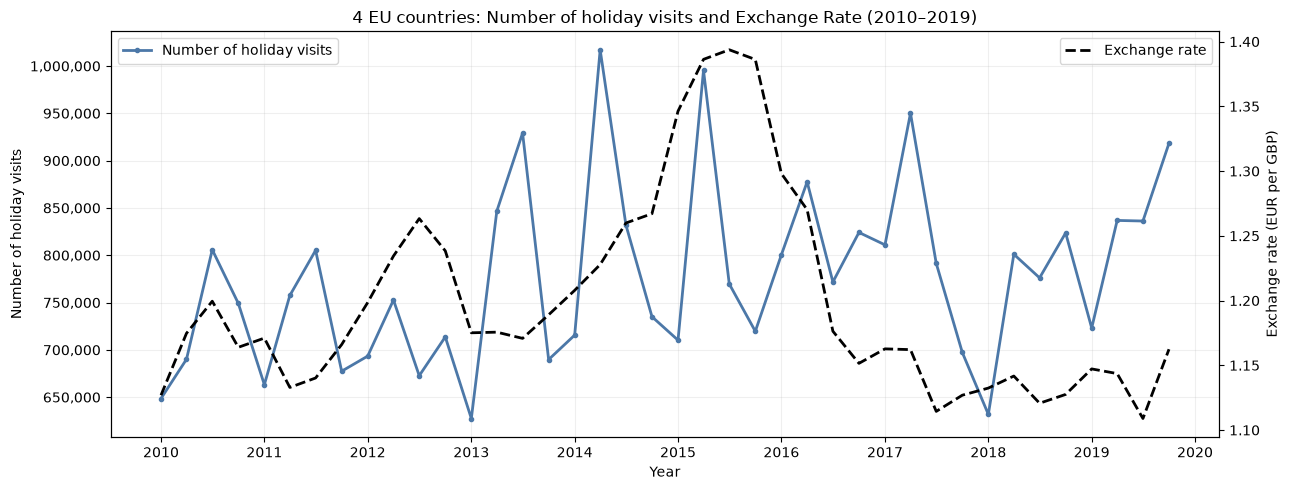

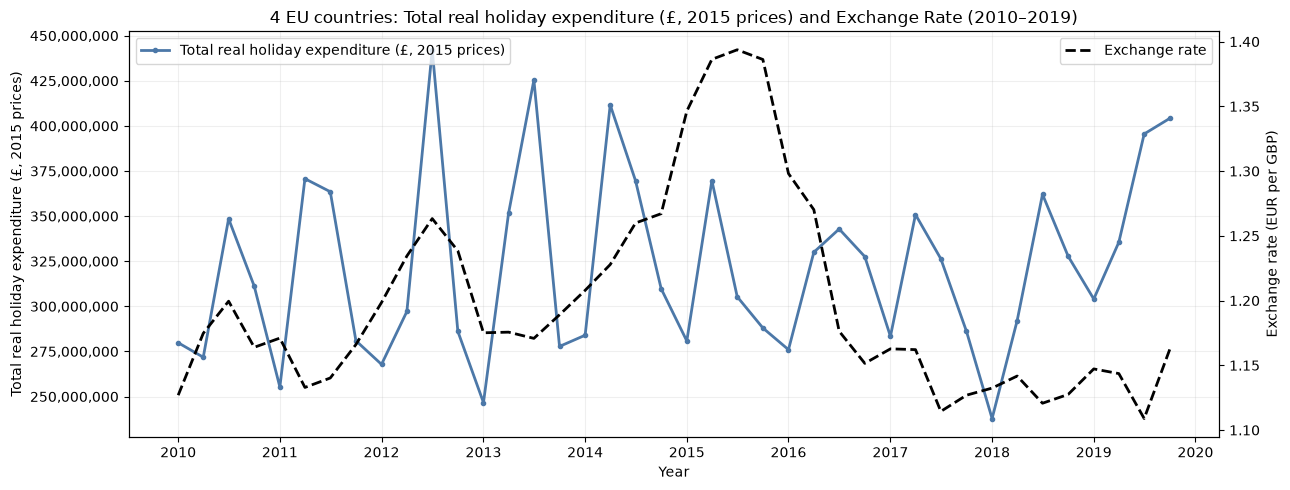

In [71]:
plot_market_trend(holiday_eur_df, "EUR", "visits",
                  "Number of holiday visits", "Holiday")
plot_market_trend(holiday_eur_df, "EUR", "real_spend_gbp",
                  "Total real holiday expenditure (£, 2015 prices)", "Holiday")

Holiday visits from the four selected EU countries exhibit strong seasonal fluctuations. However, when the exchange rate peaked, total expenditure showed a noticeable decline, while visitor numbers appeared to be less affected.

One possible explanation is that holidays are often planned and booked in advance, making travel decisions less responsive to short-term exchange-rate fluctuations. In contrast, visitors may have greater flexibility to adjust their expenditure during their stay in response to changes in purchasing power.

In particular, the increase in the exchange rate of approximately 20% around 2015–2016 coincided with a noticeable decrease in total expenditure. Although the exchange rate subsequently declined and stabilised at a lower level, expenditure did not appear to recover immediately.

This delayed recovery may reflect the advance planning involved in international holiday travel or uncertainty regarding future exchange-rate movements. However, these explanations cannot be confirmed through visual inspection alone.

In [72]:
vfr_aud_df = eda_df[(analysis_df["purpose"] == "VFR") &(analysis_df["currency"] == "AUD")]

display(vfr_aud_df.head())

/var/folders/93/dz_8fh6104x97ksqhx98m8qr0000gn/T/ipykernel_987/608546844.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  vfr_aud_df = eda_df[(analysis_df["purpose"] == "VFR") &(analysis_df["currency"] == "AUD")]


,year,quarter,currency,purpose,visits,spend_gbp,spend_per_visit,exchange_rate,cpi_index,real_spend_gbp,real_spend_per_visit,date
4,2010,1,AUD,VFR,29440,17396489,590.913349,1.7235,88.2,1.972391e+07,669.969784,2010-01-01
33,2010,2,AUD,VFR,39002,21974398,563.417209,1.6922,89.3,2.460739e+07,630.926326,2010-04-01
63,2010,3,AUD,VFR,66415,38237364,575.733855,1.7150,89.6,4.267563e+07,642.560106,2010-07-01
92,2010,4,AUD,VFR,32221,22192984,688.773905,1.6009,90.5,2.452263e+07,761.076138,2010-10-01
118,2011,1,AUD,VFR,28605,16310767,570.206852,1.5955,91.8,1.776772e+07,621.140362,2011-01-01


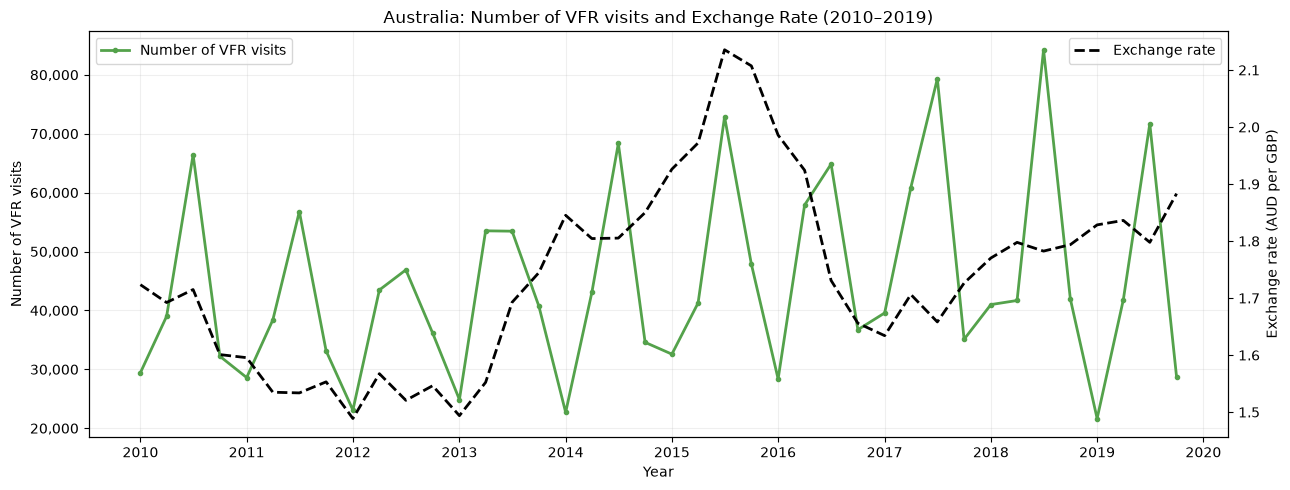

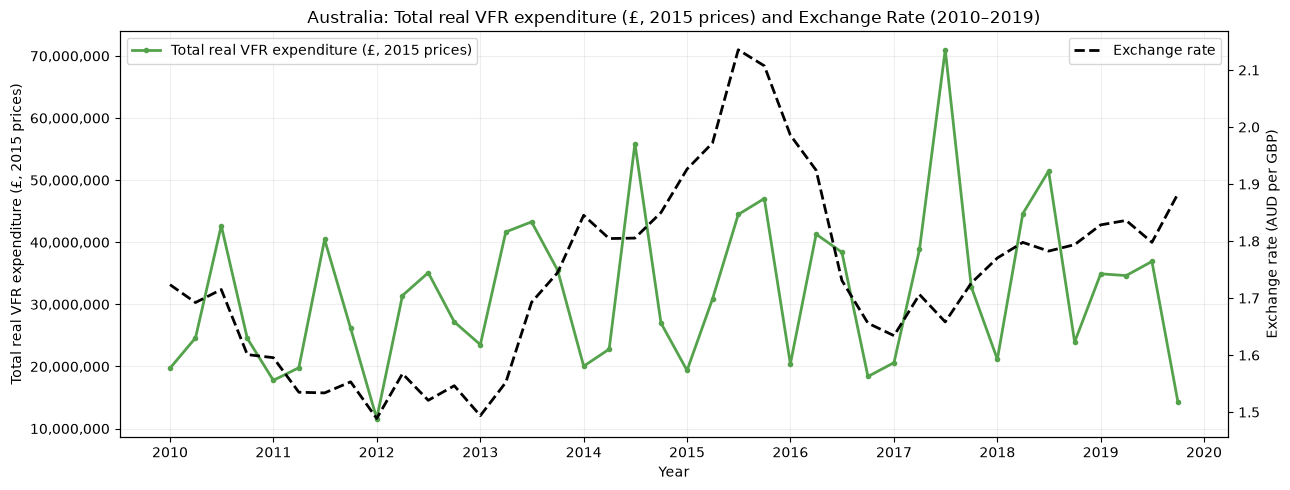

In [73]:
plot_market_trend(vfr_aud_df, "AUD", "visits",
                  "Number of VFR visits", "VFR")
plot_market_trend(vfr_aud_df, "AUD", "real_spend_gbp",
                  "Total real VFR expenditure (£, 2015 prices)", "VFR")

Similar to Holiday visits from the selected European countries, Australian VFR visits exhibit strong seasonal fluctuations.

Following the substantial depreciation of GBP against AUD between 2015 and 2017, both visitor numbers and total real expenditure increased, with expenditure showing a particularly pronounced peak in Q3 2017.

The increase in total expenditure appears disproportionately large relative to the increase in visitor numbers, suggesting that expenditure per visit may be more responsive to exchange-rate fluctuations than visitor demand.

However, this observation is based on visual inspection, and further analysis would be required to determine whether the difference reflects exchange-rate sensitivity or other factors.

In [74]:
seasonal_df = analysis_df.groupby(
    ["year", "quarter", "purpose"],
    as_index=False
).agg(
    visits=("visits", "sum"),
    real_spend_gbp=("real_spend_gbp", "sum")
)

seasonal_df["real_spend_per_visit"] = (seasonal_df["real_spend_gbp"] / seasonal_df["visits"])

In [75]:
def plot_seasonal_violin(variable, ylabel):

    fig, axes = plt.subplots(
        1, 5, figsize=(18, 5)
    )

    for ax, purpose in zip(axes, purpose_colors):

        purpose_df = seasonal_df[
            seasonal_df["purpose"] == purpose
        ]

        quarterly_data = [
            purpose_df.loc[
                purpose_df["quarter"] == q, variable
            ].dropna()
            for q in range(1, 5)
        ]

        parts = ax.violinplot(
            quarterly_data,
            showmedians=True,
            showextrema=True
        )

        for body in parts["bodies"]:
            body.set_facecolor(purpose_colors[purpose])
            body.set_alpha(0.5)

        ax.set_title(purpose)
        ax.set_xticks([1, 2, 3, 4])
        ax.set_xticklabels(["Q1", "Q2", "Q3", "Q4"])
        ax.set_xlabel("Quarter")

        ax.yaxis.set_major_formatter(
            ticker.StrMethodFormatter("{x:,.0f}")
        )

        ax.grid(axis="y", alpha=0.2)

    axes[0].set_ylabel(ylabel)

    fig.suptitle(
        f"Seasonal Distribution of {ylabel} "
        "(2010–2019)"
    )

    plt.tight_layout()
    plt.show()

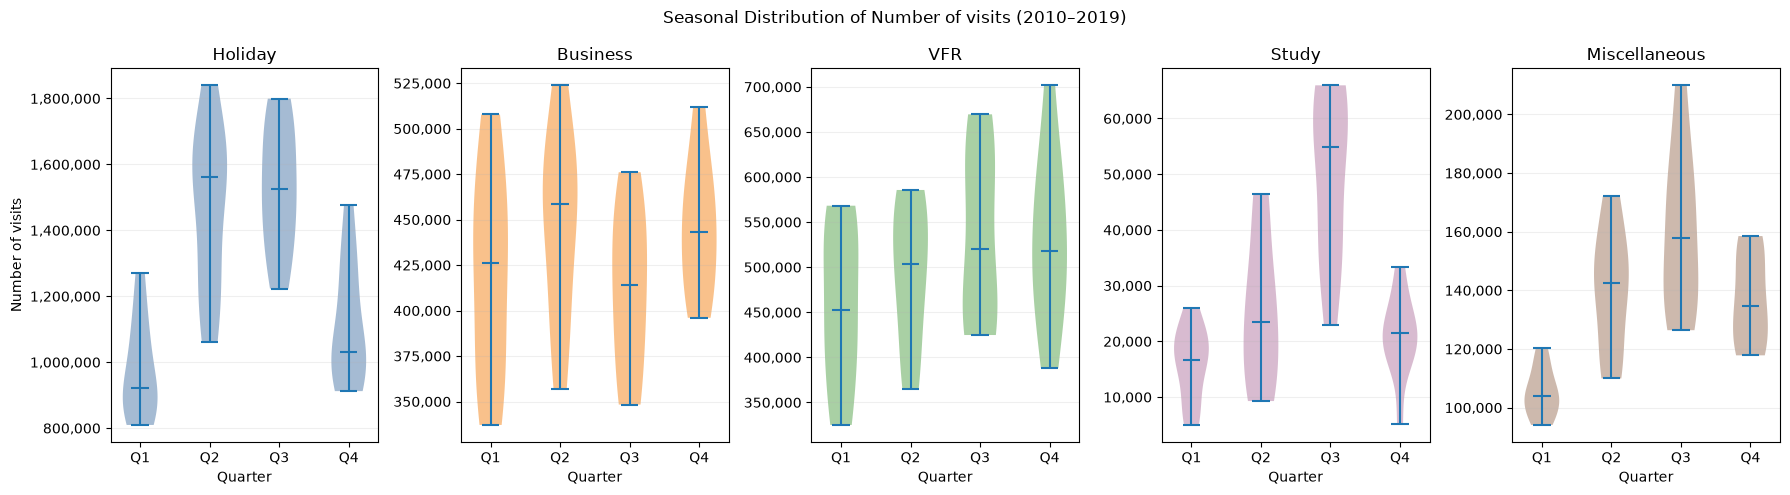

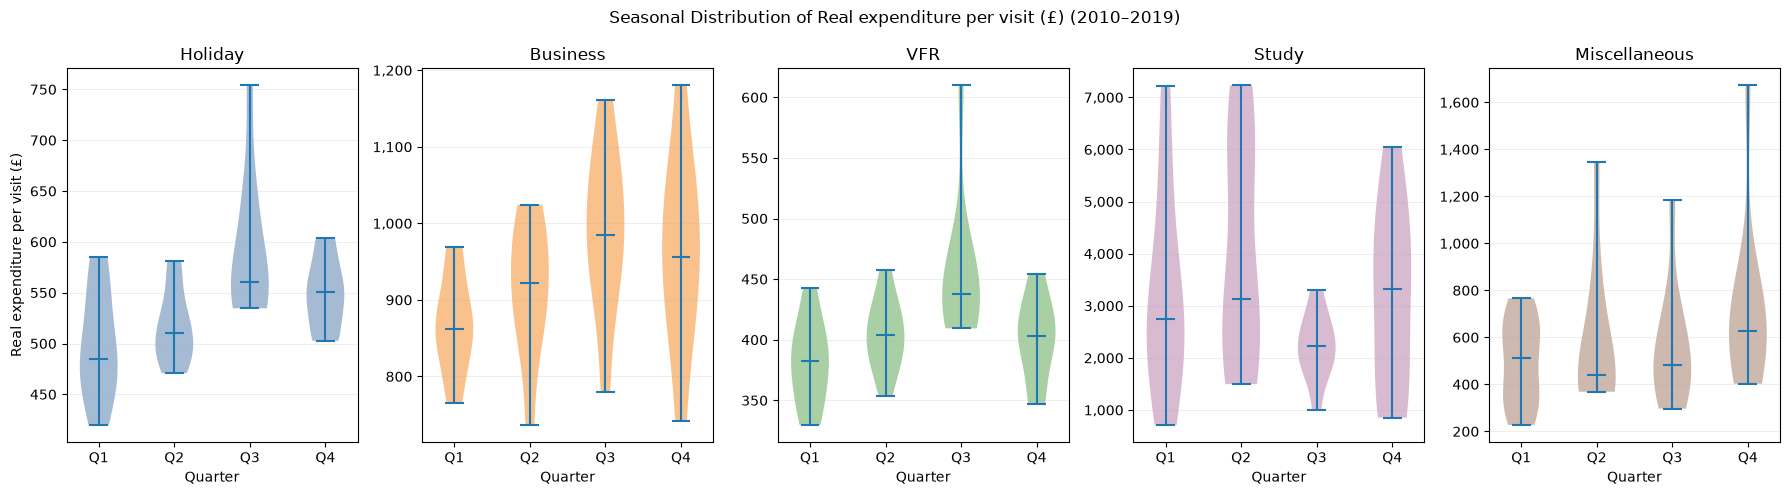

In [76]:
plot_seasonal_violin("visits", "Number of visits")

plot_seasonal_violin("real_spend_per_visit","Real expenditure per visit (£)")

Seasonal fluctuations appear more pronounced in visitor numbers than in real expenditure per visit for Holiday and Study. Holiday visits exhibit particularly high demand in Q2 and Q3, whereas Study visits show a distinct peak in Q3, potentially reflecting the academic calendar.

Interestingly, despite the substantial increase in study-related visits in Q3, median real expenditure per visit is lower and its distribution is narrower than in other quarters.

Business and VFR visits exhibit less distinct seasonal patterns, although some seasonal differences are observable in expenditure per visit. Miscellaneous visits also show noticeable seasonal variation, with demand peaking in Q3.

However, since the data are aggregated across all selected source markets, differences in country-specific seasonal patterns may offset one another. Furthermore, larger markets may disproportionately influence the aggregated results, potentially masking seasonal characteristics of individual markets.

In [77]:
trend_df = eda_df

In [78]:
def plot_all_purpose_visits(currency):

    market_df = trend_df[
        trend_df["currency"] == currency
    ]

    fig, ax1 = plt.subplots(figsize=(14, 6))

    # Complete quarterly timeline
    dates = pd.date_range(
        "2010-01-01", "2019-10-01", freq="QS"
    )

    # Left axis: visits by purpose
    for purpose, color in purpose_colors.items():

        purpose_df = market_df[
            market_df["purpose"] == purpose
        ].set_index("date").reindex(dates)

        ax1.plot(
            purpose_df.index,
            purpose_df["visits"],
            color=color,
            linewidth=2,
            label=purpose
        )

    ax1.set_xlabel("Year")
    ax1.set_ylabel("Number of visits")
    ax1.set_ylim(bottom=0)

    ax1.yaxis.set_major_formatter(
        ticker.StrMethodFormatter("{x:,.0f}")
    )

    # Right axis: exchange rate
    ax2 = ax1.twinx()

    ax2.plot(
        dates,
        fx_df.sort_values(["year", "quarter"])[currency],
        color="black",
        linestyle="--",
        linewidth=2,
        label="Exchange rate"
    )

    ax2.set_ylabel(f"Exchange rate ({currency} per GBP)")

    # Format timeline
    ax1.xaxis.set_major_locator(mdates.YearLocator())
    ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

    # Combine legends
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()

    ax1.legend(
        lines1 + lines2,
        labels1 + labels2,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.12),
        ncol=6
    )

    ax1.grid(alpha=0.2)

    plt.title(
        f"{market_names[currency]}: Quarterly Visits by Purpose "
        f"and Exchange Rate (2010–2019)"
    )

    plt.tight_layout()
    plt.show()

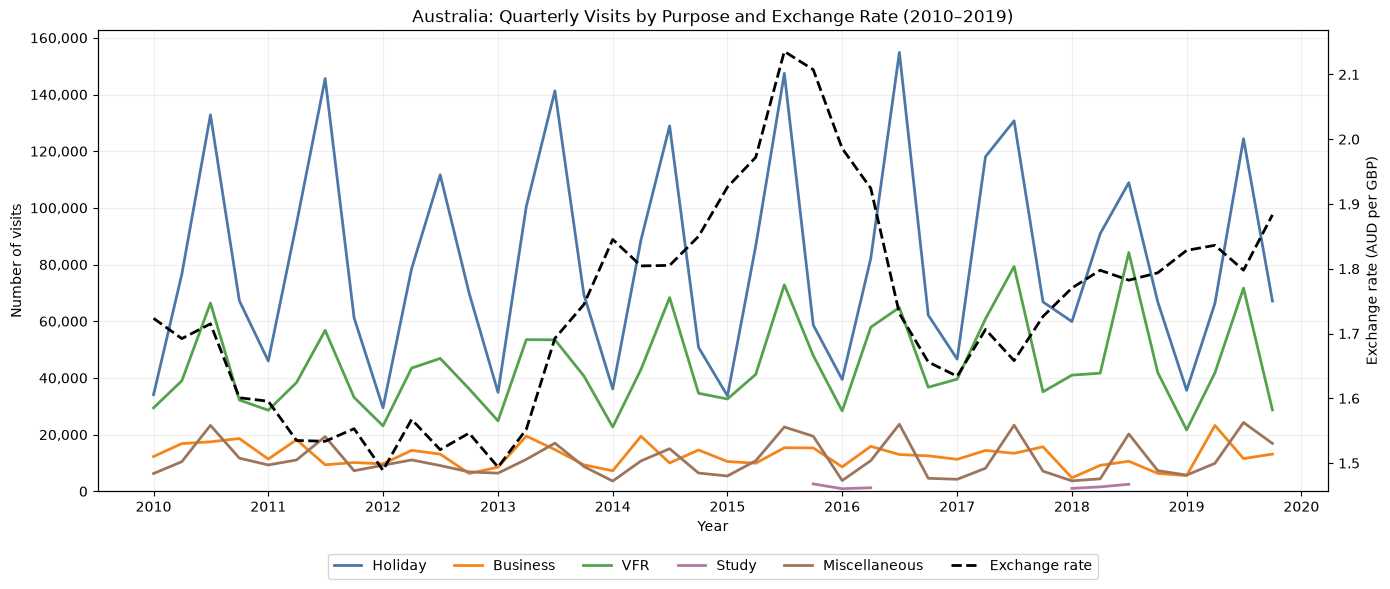

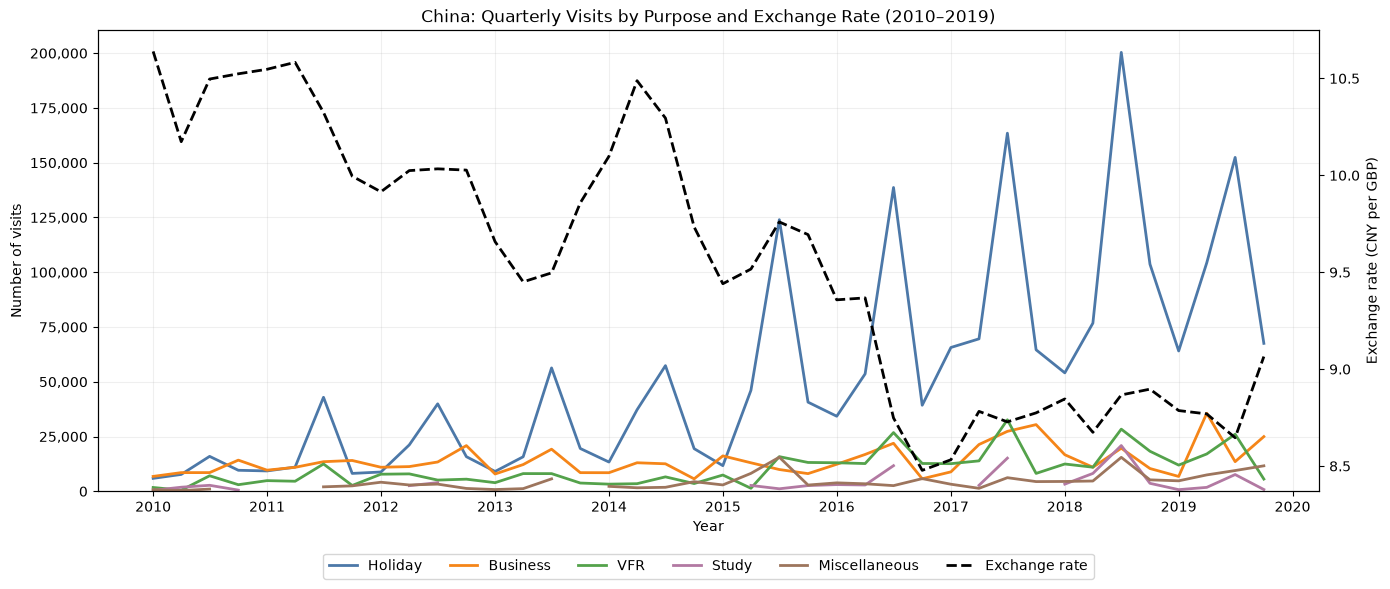

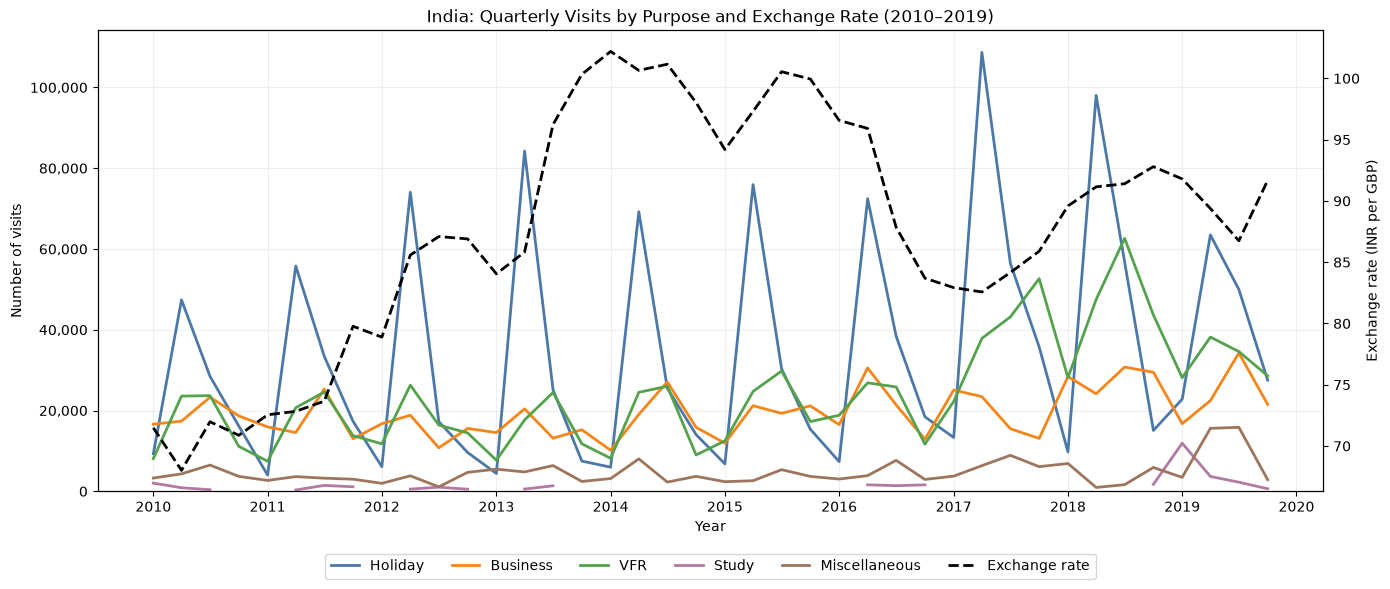

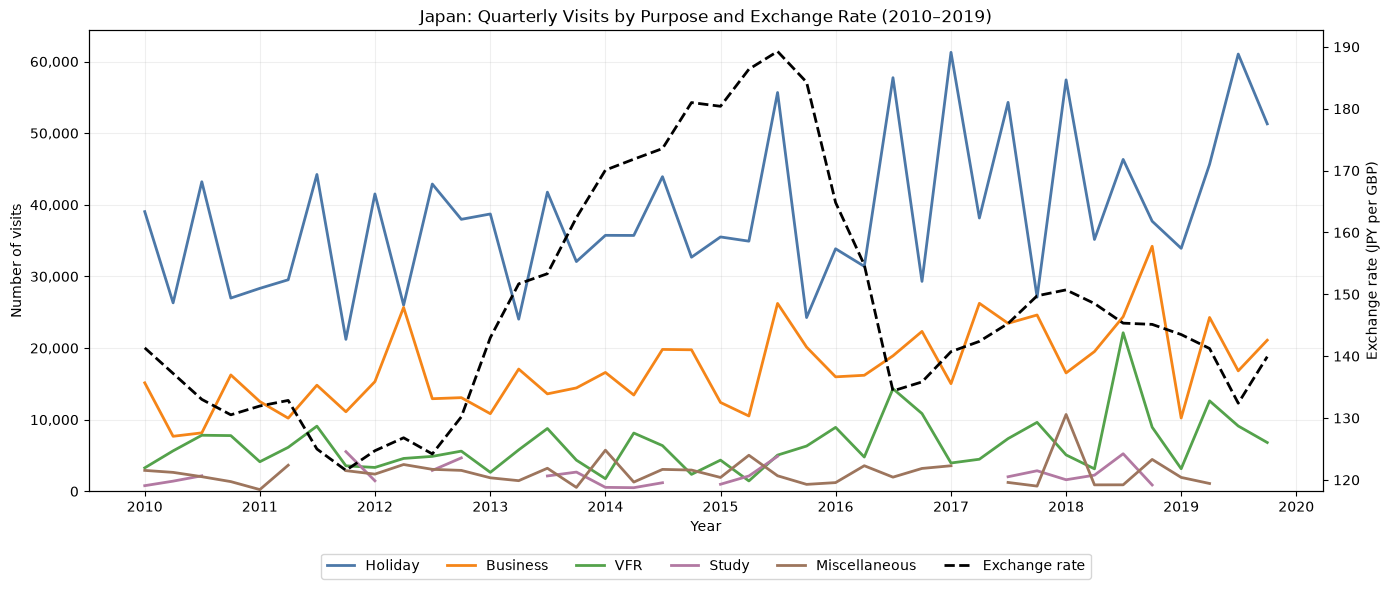

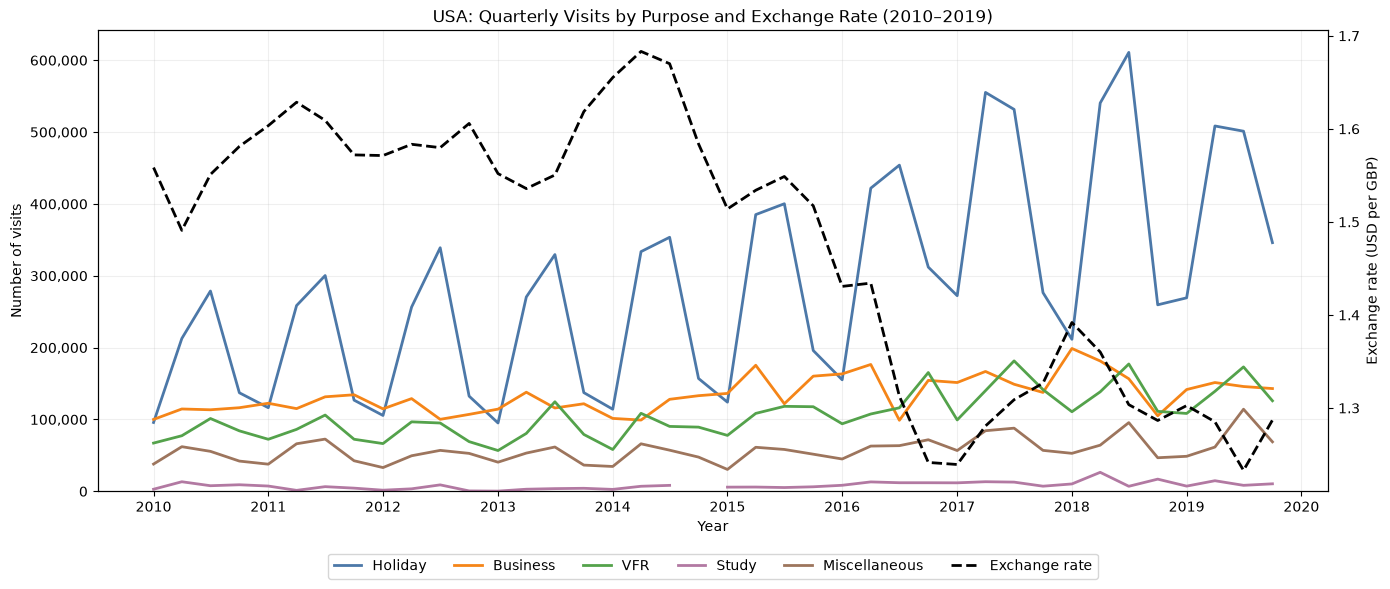

In [79]:
currencies = ["AUD", "CNY", "INR", "JPY", "USD"]

for currency in currencies:
    plot_all_purpose_visits(currency)

in the graph, except for Australia, visits seem to have negative correlation with exchange rate especially for the purpose of holiday and VFR. however considering the total number of visits are much lower accounting in other purposes, the fluctuation could have been hidden and need further checks